# Regresión de potencia eléctrica: exploración

Consulta la [metodología](../docs/metodologia.md) y ejecuta las etapas en orden. Los comentarios se calculan con los resultados guardados.

In [1]:
from pathlib import Path
import sys
here = Path.cwd().resolve()
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("power_plant_regression")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre este notebook desde su proyecto independiente.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from power_plant_regression.alerts import configurar_notebook, mostrar_alertas
from IPython.display import display, Markdown, Image
configurar_notebook()


# Regresión de potencia eléctrica: eda

Train contiene **5716 observaciones**. Correlación temperatura–potencia **-0.948**, asociación **fuerte** bajo la regla declarada. Esta clasificación se actualiza con los datos y no implica causalidad. Multicolinealidad entre AT, V, AP y RH: VIF máximo **6.07** en **AT**, nivel **moderada** (umbral descriptivo VIF>=10 alta, >=5 moderada). Un VIF alto afecta la interpretación de coeficientes en Ridge, no la capacidad predictiva del modelo elegido por MAE. El dataset corresponde a operación a plena carga; no acredita desempeño en otros regímenes.


,Indicador,Valor
0,filas_train,5716
1,potencia_media_mw,453.926198
2,correlacion_temperatura_potencia,-0.948434
3,criterios_correlacion,|r| >=0.7 fuerte; >=0.4 moderada; resto débil;...
4,vif_maximo,6.068487
5,vif_variable_maxima,AT
6,multicolinealidad,moderada


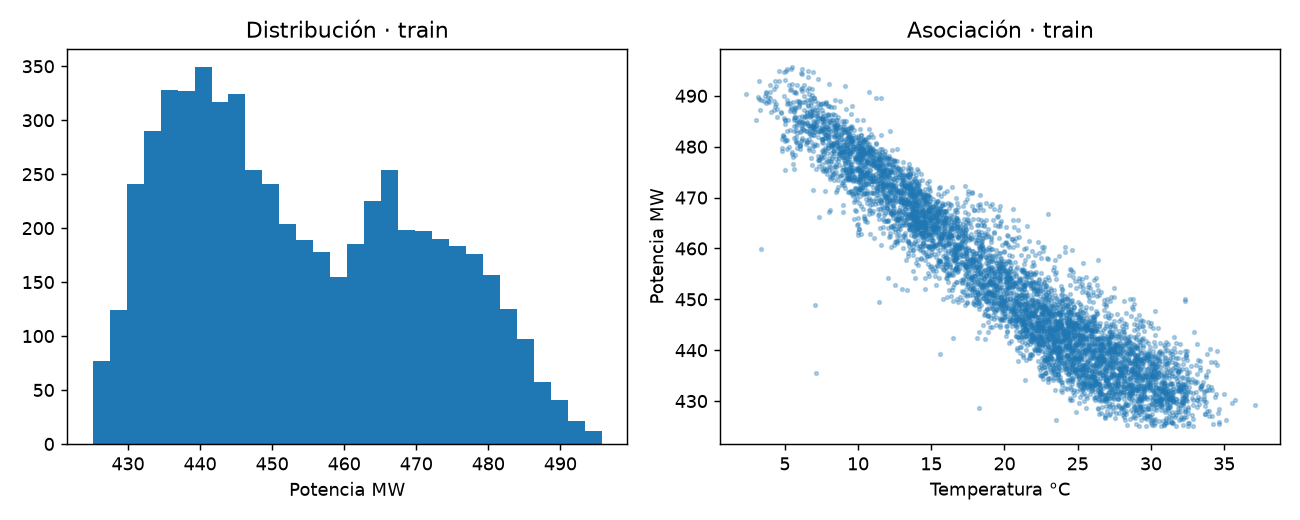

In [2]:
from power_plant_regression.analysis import run_stage
import pandas as pd
metrics,comment=run_stage(PROJECT_ROOT,"eda")
display(Markdown(comment))
scalars={k:v for k,v in metrics.items() if not isinstance(v,(dict,list))}
if scalars:display(pd.DataFrame(list(scalars.items()),columns=["Indicador","Valor"]))
if "candidatos" in metrics:display(pd.DataFrame(metrics["candidatos"]))
for filename in ["eda.png","evaluacion.png"]:
    path=PROJECT_ROOT/"reports/eda"/filename
    if path.exists():display(Image(filename=str(path)))
for filename in ["estimaciones.csv","metricas_test.csv","horas_por_empleado.csv"]:
    path=PROJECT_ROOT/"reports/eda"/filename
    if path.exists():display(pd.read_csv(path).head(20))

In [3]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/02_analisis_exploratorio.json")
from power_plant_regression.informe import generar_informe
generar_informe(PROJECT_ROOT)
display(Markdown("[Abrir informe integral](../reports/informe_final/informe_final.md)"))

[Abrir informe integral](../reports/informe_final/informe_final.md)